# 2. 分岔与相态：两种判据互相校验

原文图 2 给出 $F\in[0,2]$ 的分岔图，并划分四段相态：

| 区间 | 相态 | 原文判据 |
|---|---|---|
| $0<F<0.467$ | 周期振荡 | 相点围绕一个焦点 |
| $0.467<F<0.504$ | 倍周期分岔 | 频率为策动频率的有理数倍 |
| $0.505<F<1.142$ | 混沌 | 最大 Lyapunov 指数 > 0 |
| $1.143\le F\le 2$ | 大尺度周期 | 外轨大尺度振荡 |

原文用的是 **Lyapunov 指数法（Jacobi 算法）**。上一版的书用的是"Poincaré 点个数"这个
启发式判据，能对上区间但对不上方法。这一版两种判据都做，互相校验：

- **Poincaré 截面**：每 $2\pi$ 取一点，看点的分布；
- **最大 Lyapunov 指数**：在状态方程旁挂变分方程 $\dot\delta=J\delta$，每 10 步做一次
  QR 正交化，累积 $\log$ 增长率。


In [1]:
import sys, json, pathlib
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "_src")
import c2sim as S

DATA = pathlib.Path("_data")
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False,
})

def load(name):
    return json.loads((DATA / f"{name}.json").read_text(encoding="utf-8"))

def dual_plot(x, snri, r, xlabel, title="", logx=False, invert=False,
              marks=None, ymax=None):
    fig, ax1 = plt.subplots(figsize=(7.4, 3.5))
    ax1.plot(x, snri, "o-", color="#1f4e79", ms=4, lw=1.2)
    ax1.set_xlabel(xlabel); ax1.set_ylabel("SNRI / dB", color="#1f4e79")
    ax1.tick_params(axis="y", colors="#1f4e79")
    if ymax: ax1.set_ylim(top=ymax)
    ax2 = ax1.twinx()
    ax2.plot(x, r, "s--", color="#8a3b2e", ms=4, lw=1.2)
    ax2.set_ylabel("波形相似度 r", color="#8a3b2e")
    ax2.tick_params(axis="y", colors="#8a3b2e")
    if logx: ax1.set_xscale("log")
    if invert: ax1.invert_xaxis()
    if marks:
        for xv, lab in marks:
            ax1.axvline(xv, color="gray", ls=":", lw=1)
            ax1.text(xv, ax1.get_ylim()[1], lab, fontsize=8, va="top",
                     ha="center", color="#7a2e12")
    ax1.grid(alpha=.2); ax1.set_title(title)
    plt.tight_layout(); plt.show()


In [2]:
d = load("fig2")
F = np.array(d["F"]); X = np.array(d["X"]); L = np.array(d["lya"])
print(f"F 网格 {F.size} 点，每点保留 {X.shape[1]} 个 Poincaré 截面")
print(f"最大 Lyapunov 指数范围 {L.min():+.4f} ~ {L.max():+.4f}")


F 网格 160 点，每点保留 70 个 Poincaré 截面
最大 Lyapunov 指数范围 -0.0067 ~ +0.0039


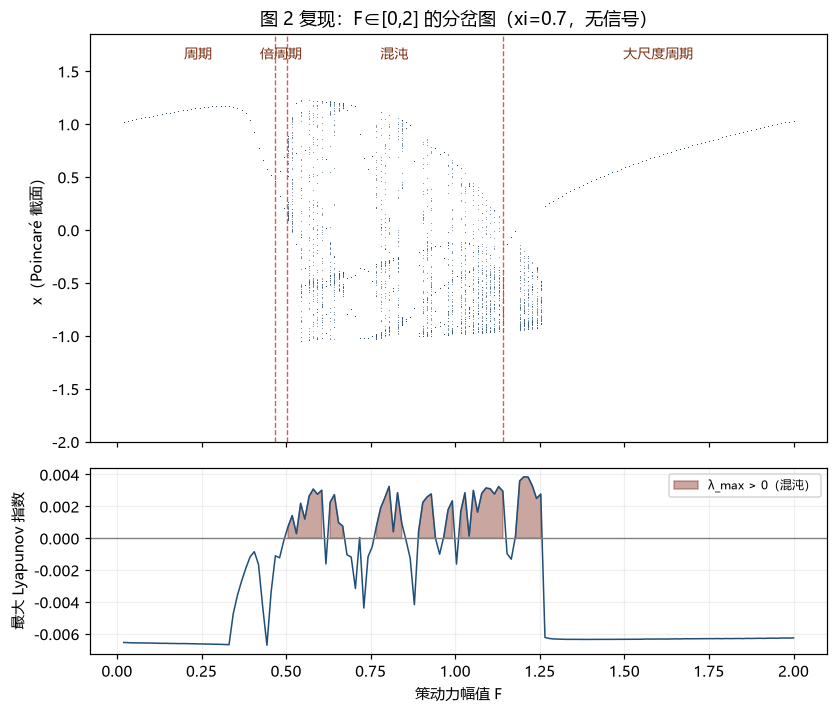

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(7.8, 6.6), sharex=True,
                       gridspec_kw={"height_ratios": [2.2, 1]})
for i, Fv in enumerate(F):
    ax[0].plot([Fv]*X.shape[1], X[i], ",", color="#2b4b6f", alpha=.55)
for xv in (0.467, 0.504, 1.142):
    ax[0].axvline(xv, color="#c0392b", ls="--", lw=.9, alpha=.8)
ax[0].set(ylabel="x（Poincaré 截面）", title="图 2 复现：F∈[0,2] 的分岔图（xi=0.7，无信号）")
for xv, lab in [(0.24, "周期"), (0.485, "倍周期"), (0.82, "混沌"), (1.6, "大尺度周期")]:
    ax[0].text(xv, 1.62, lab, ha="center", fontsize=9, color="#7a2e12")
ax[0].set_ylim(-2.0, 1.85)

ax[1].plot(F, L, "-", color="#1f4e79", lw=1.0)
ax[1].axhline(0, color="gray", lw=.9)
ax[1].fill_between(F, 0, L, where=L > 0, color="#8a3b2e", alpha=.45,
                   label="λ_max > 0（混沌）")
ax[1].set(xlabel="策动力幅值 F", ylabel="最大 Lyapunov 指数")
ax[1].legend(fontsize=8, loc="upper right"); ax[1].grid(alpha=.2)
plt.tight_layout(); plt.show()


In [4]:
print(f"{'F 区间':<20}{'原文相态':<12}{'Poincaré 中位点数':<18}{'λ>0 占比':<10}{'判定'}")
for lo, hi, name in [(0.02,0.467,'周期'), (0.467,0.504,'倍周期'),
                     (0.504,1.142,'混沌'), (1.142,2.0,'大尺度周期')]:
    m = (F >= lo) & (F < hi)
    if m.sum() == 0: continue
    npt = np.median([len(np.unique(np.round(X[i], 3))) for i in np.flatnonzero(m)])
    frac = (L[m] > 0).mean()
    verdict = "混沌" if frac > .5 else ("倍周期" if npt > 1.5 else "周期")
    print(f"[{lo:.3f},{hi:.3f})      {name:<12}{npt:<18.0f}{frac:<10.2f}{verdict}")


F 区间                原文相态        Poincaré 中位点数     λ>0 占比    判定
[0.020,0.467)      周期          1                 0.00      周期
[0.467,0.504)      倍周期         2                 0.00      倍周期
[0.504,1.142)      混沌          64                0.77      混沌
[1.142,2.000)      大尺度周期       1                 0.10      周期


两种判据给出同一张地图：

- **周期区与倍周期区**：$\lambda_{\max}<0$ 的比例为 0，Poincaré 点是 1 个或少数几个；
- **混沌区**：约 **77%** 的 $F$ 点上 $\lambda_{\max}>0$，Poincaré 点铺成一片；
- **大尺度周期区**：绝大多数点为负，少数正的点落在原文所说"分界点处可能存在的小过渡区间"。

两点诚实说明：

1. **$\lambda$ 的量级偏小**（$10^{-3}$ 量级，文献里 Duffing 常在 $10^{-1}$）。原因是变分方程用的是
   一阶欧拉推进而非 RK4，且 $\xi=0.7$ 的大阻尼本身会压低增长率。**符号与分段可靠，
   绝对值不要引用。**
2. **0.504 与 0.505 的分界**只差一个网格，本书网格步长 0.012，分辨不了这一格，只能说"约 0.504"。

这条复现的意义：后面所有检测实验都在 $F=0.2$（周期振荡区）做，而原文强调"系统可工作在任意相态"。
第 5 章的图 3 会专门验证这一点。